In [11]:
%pip install faiss-cpu

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/16.2 MB ? eta -:--:--
   ----------- ---------------------------- 4.7/16.2 MB 35.7 MB/s eta 0:00:01
   --------------------- ------------------ 8.7/16.2 MB 25.6 MB/s eta 0:00:01
   ------------------------------- -------- 12.6/16.2 MB 23.2 MB/s eta 0:00:01
   ---------------------------------------  16.0/16.2 MB 21.9 MB/s eta 0:00:01
   ---------------------------------------- 16.2/16.2 MB 20.3 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: C:\Users\lalan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

In [2]:
load_dotenv()  # Load environment variables from .env file

True

In [3]:
llm = ChatOpenAI(model='gpt-4o-mini')

In [4]:
loader = PyPDFLoader("intro-to-ml.pdf")
docs = loader.load()

In [5]:
len(docs)

392

In [8]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
chunks = splitter.split_documents(docs)
len(chunks)

934

In [ ]:
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')


In [15]:
local_vectorstore = FAISS.load_local("faiss_index", embeddings, allow_dangerous_deserialization=True)

In [18]:
if local_vectorstore is None:
    print("Failed to load vectorstore.")
    vectorstore = FAISS.from_documents(chunks, embeddings)
    vectorstore.save_local("faiss_index")
else:
    print("Vectorstore loaded successfully from Local.")
    vectorstore = local_vectorstore


Vectorstore loaded successfully from Local.


In [25]:
@tool
def rag_tool(query: str) -> str:
    """
    A tool that uses a vectorstore to retrieve relevant documents based on a query.
    """
    results = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 3})
    retrieved_docs = results.get_relevant_documents(query)
    context = [doc.page_content for doc in retrieved_docs]
    metadata = [doc.metadata for doc in retrieved_docs]
    return{
        
        "query": query,
        "context": context,
        "metadata": metadata
    }

In [26]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [27]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    

In [50]:
def tools_condition1(state: ChatState) -> str:
    """
    Determines whether to use the RAG tool based on the last user message.
    """
    last_message = state["messages"][-1] if state["messages"] else None
    if isinstance(last_message, HumanMessage) and "search" in last_message.content.lower():
        return "tool_node"
    return "chat_node"

In [43]:
def chat_node(state:ChatState):
    messages = state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [40]:
tool_node = ToolNode(tools)

In [51]:
graph = StateGraph(ChatState)
graph.add_node("chat_node",chat_node)
graph.add_node("tool_node", tool_node)

graph.add_edge(START,'chat_node')
graph.add_conditional_edges('chat_node', tools_condition1)
graph.add_edge('tool_node', 'chat_node')


chatbot = graph.compile()

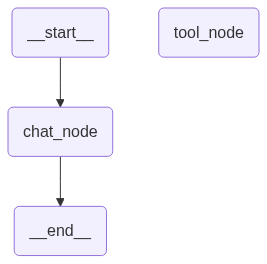

In [53]:
chatbot